# The Catalyst Optimizer & Execution Plans

You write a Spark query as a chain of DataFrame steps or as SQL. Spark does not run these steps in the order you
wrote them. The **Catalyst optimizer** first rewrites the query into an equivalent plan that reads less data and
does less work. Then the **Adaptive Query Execution** (AQE) engine changes the plan again while it runs, with the
real data sizes. If you can read a plan, you can see why a query is slow and what to change.

**After this lesson you can:**

1. Read the logical, optimized and physical plans of a query with `explain()`.
2. Show column pruning, predicate pushdown, constant folding and filter combination in a plan, and measure the
   bytes and rows that Spark reads.
3. Explain why a Python UDF blocks the optimizer, and measure the cost.
4. Compare a query with AQE on and off: shuffle partitions, join strategy and time.

**Data:** NYC yellow taxi trips, January 2024 (2.96 million rows).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import contextlib
import io
import re
import os
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import pyspark
import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "l02"
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir(parents=True)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"                 # no hostname warning
os.environ["TZ"] = "UTC"; time.tzset()                     # one time zone for the JVM and the Python workers
LOG4J = WORK / "log4j2.properties"                           # only errors from the JVM, no start-up messages
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
                 "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n"
                 "logger.repl.name = org.apache.spark.repl.Main\nlogger.repl.level = error\n")
TRIPS = str(shutil.copy(datasets.taxi("2024-01"), WORK / "trips_2024-01.parquet"))   # local disk: fair timings

spark = (SparkSession.builder.master("local[4]").appName("m13-l02")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false").config("spark.sql.session.timeZone", "UTC")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j.configurationFile=file:{LOG4J} -XX:MaxDirectMemorySize=256m -Duser.timezone=UTC").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def api(path: str):
    sc = spark.sparkContext
    return requests.get(f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}", timeout=10).json()

def run_tagged(tag: str, action):
    """Run an action under a job group; return (result, seconds)."""
    sc = spark.sparkContext
    sc.setJobGroup(tag, tag)
    t0 = time.perf_counter()
    result = action()
    secs = time.perf_counter() - t0
    sc.setLocalProperty("spark.jobGroup.id", None)
    return result, secs

def metrics(tag: str) -> dict:
    """Sum the metrics of all completed stages of one job group (from the REST API)."""
    time.sleep(0.5)
    for _ in range(50):
        jobs = [j for j in api("jobs") if j.get("jobGroup") == tag]
        if jobs and all(j["status"] != "RUNNING" for j in jobs):
            break
        time.sleep(0.2)
    ids = sorted({s for j in jobs for s in j["stageIds"]})
    st = [a for sid in ids for a in api(f"stages/{sid}?details=false") if a["status"] == "COMPLETE"]
    return {"jobs": len(jobs), "stages": len(st), "tasks": sum(s["numTasks"] for s in st),
            "input MB": round(sum(s["inputBytes"] for s in st) / 1e6, 2),
            "input rows": sum(s["inputRecords"] for s in st),
            "shuffle MB": round(sum(s["shuffleWriteBytes"] for s in st) / 1e6, 3)}

def plan(df, mode: str = "formatted") -> str:
    """The text of df.explain(mode)."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain(mode=mode)
    return buf.getvalue()

JVM_PID = spark._jvm.java.lang.ProcessHandle.current().pid()

def jvm_read_bytes() -> int:
    """Bytes the Spark JVM has read through read() calls so far (Linux /proc counter `rchar`)."""
    with open(f"/proc/{JVM_PID}/io") as f:
        return int(next(line for line in f if line.startswith("rchar")).split()[1])

trips = spark.read.parquet(TRIPS)
print("Spark", pyspark.__version__, "|", f"{trips.count():,} rows,", len(trips.columns), "columns")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.2.0 | 2,964,624 rows, 19 columns


## 1. From Query to Physical Plan

Catalyst works in four phases:

| Phase | Input → output | Example work |
| :--- | :--- | :--- |
| **Parsing** | your code or SQL → parsed logical plan | build a tree of operators; names are not checked yet |
| **Analysis** | parsed → analyzed logical plan | resolve column names and types from the catalog and the file schema |
| **Optimization** | analyzed → optimized logical plan | rule-based rewrites: prune columns, push filters, fold constants |
| **Physical planning** | optimized → physical plan | choose algorithms: hash aggregate, sort-merge or broadcast join, file scan options |

A **logical plan** says *what* to compute. A **physical plan** says *how*. `explain(mode="extended")` prints all
four plans. The query below computes the average tip percentage per payment type.

In [2]:
tips = (trips.filter(F.col("trip_distance") > 0)
             .withColumn("tip_pct", F.col("tip_amount") / F.col("fare_amount") * 100)
             .filter(F.col("fare_amount") > 5)
             .groupBy("payment_type")
             .agg(F.round(F.avg("tip_pct"), 2).alias("avg_tip_pct"), F.count("*").alias("trips")))
tips.explain(mode="extended")

== Parsed Logical Plan ==
'Aggregate ['payment_type], ['payment_type, 'round('avg('tip_pct), 2) AS avg_tip_pct#44, 'count(*) AS trips#45]
+- Filter (fare_amount#10 > cast(5 as double))
   +- Project [VendorID#0, tpep_pickup_datetime#1, tpep_dropoff_datetime#2, passenger_count#3L, trip_distance#4, RatecodeID#5L, store_and_fwd_flag#6, PULocationID#7, DOLocationID#8, payment_type#9L, fare_amount#10, extra#11, mta_tax#12, tip_amount#13, tolls_amount#14, improvement_surcharge#15, total_amount#16, congestion_surcharge#17, Airport_fee#18, ((tip_amount#13 / fare_amount#10) * cast(100 as double)) AS tip_pct#43]
      +- Filter (trip_distance#4 > cast(0 as double))
         +- Relation [VendorID#0,tpep_pickup_datetime#1,tpep_dropoff_datetime#2,passenger_count#3L,trip_distance#4,RatecodeID#5L,store_and_fwd_flag#6,PULocationID#7,DOLocationID#8,payment_type#9L,fare_amount#10,extra#11,mta_tax#12,tip_amount#13,tolls_amount#14,improvement_surcharge#15,total_amount#16,congestion_surcharge#17,Airport_fe

Read the plans from the bottom up. In the analyzed plan, the two filters are separate and the `Relation` lists all
19 columns. In the optimized plan, Catalyst combined the two filters into one and added `isnotnull` checks. The
`Relation` still lists all 19 columns. The physical scan reads only the 4 columns that the query uses (`ReadSchema`). The physical plan replaces `Aggregate` by two
`HashAggregate` steps around an `Exchange`. `explain(mode="formatted")` prints the physical plan as a short tree plus
the details of each node. The scan node shows what Spark asks the Parquet reader for.

In [3]:
print(plan(tips, "formatted"))
print(tips.orderBy("payment_type").toPandas().to_string(index=False))

== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [4]: [trip_distance#4, payment_type#9L, fare_amount#10, tip_amount#13]
Batched: true
Location: InMemoryFileIndex [file:/tmp/fzth-m13/l02/trips_2024-01.parquet]
PushedFilters: [IsNotNull(trip_distance), IsNotNull(fare_amount), GreaterThan(trip_distance,0.0), GreaterThan(fare_amount,5.0)]
ReadSchema: struct<trip_distance:double,payment_type:bigint,fare_amount:double,tip_amount:double>

(2) Filter
Input [4]: [trip_distance#4, payment_type#9L, fare_amount#10, tip_amount#13]
Condition : (((isnotnull(trip_distance#4) AND isnotnull(fare_amount#10)) AND (trip_distance#4 > 0.0)) AND (fare_amount#10 > 5.0))

(3) Project
Output [2]: [payment_type#9L, ((tip_amount#13 / fare_amount#10) * 100.0) AS tip_pct#43]
Input [4]: [trip_distance#4, payment_type#9L, fare_amount#10, tip_amount

 payment_type  avg_tip_pct   trips
            0         9.01  113435
            1        25.25 2270313
            2         0.00  412023
            3         0.04    9122
            4         0.03   20690


## 2. Constant Folding and Filter Combination

Some rewrites remove work that you wrote by accident or that a code generator produced:

- **Constant folding** computes expressions on literals once, during planning: `10 * 2` becomes `20`.
- **Filter combination** merges consecutive filters into one `Filter` with `AND`.
- **Filter pushdown through a projection** moves a filter below a `select`/`withColumn`, closer to the data.
- **Boolean simplification** removes conditions that are always true, such as `1 = 1`.

The query below has three filters, a constant expression and a filter after the `select`.

In [4]:
messy = (trips.withColumn("fare_x2", F.col("fare_amount") * (F.lit(1) + F.lit(1)))
              .filter(F.col("fare_amount") > F.lit(10) * 2)
              .filter(F.lit(1) == 1)
              .select("PULocationID", "fare_amount", "fare_x2")
              .filter(F.col("PULocationID") == 132))
qe = messy._jdf.queryExecution()
analyzed, optimized = qe.analyzed().toString(), qe.optimizedPlan().toString()
print("ANALYZED (as written):\n" + analyzed)
print("OPTIMIZED:\n" + optimized)
for name, text in [("analyzed", analyzed), ("optimized", optimized)]:
    ops = [line.strip(" +-:").split(" ")[0] for line in text.splitlines()]
    print(f"{name:<9}: {ops.count('Filter')} Filter node(s), {ops.count('Project')} Project node(s)")

ANALYZED (as written):
Filter (PULocationID#7 = 132)
+- Project [PULocationID#7, fare_amount#10, fare_x2#82]
   +- Filter (1 = 1)
      +- Filter (fare_amount#10 > cast((10 * 2) as double))
         +- Project [VendorID#0, tpep_pickup_datetime#1, tpep_dropoff_datetime#2, passenger_count#3L, trip_distance#4, RatecodeID#5L, store_and_fwd_flag#6, PULocationID#7, DOLocationID#8, payment_type#9L, fare_amount#10, extra#11, mta_tax#12, tip_amount#13, tolls_amount#14, improvement_surcharge#15, total_amount#16, congestion_surcharge#17, Airport_fee#18, (fare_amount#10 * cast((1 + 1) as double)) AS fare_x2#82]
            +- Relation [VendorID#0,tpep_pickup_datetime#1,tpep_dropoff_datetime#2,passenger_count#3L,trip_distance#4,RatecodeID#5L,store_and_fwd_flag#6,PULocationID#7,DOLocationID#8,payment_type#9L,fare_amount#10,extra#11,mta_tax#12,tip_amount#13,tolls_amount#14,improvement_surcharge#15,total_amount#16,congestion_surcharge#17,Airport_fee#18] parquet

OPTIMIZED:
Project [PULocationID#7, far

*Insight: The analyzed plan has 3 `Filter` and 2 `Project` nodes, in the order of the code. The optimized plan has 1 `Filter` and 1 `Project`. Catalyst folded `10 * 2` into `20.0` and `1 + 1` into `2.0`, and it removed the condition `1 = 1`. It also moved the filter on `PULocationID` below the `select`. All conditions are now in one `Filter` next to the data, with `isnotnull` checks added.*

## 3. Column Pruning and Predicate Pushdown on Parquet

Parquet stores each column separately, in **row groups** of many rows. The footer stores the min and max value of
each column in each row group. This gives two ways to read less:

- **Column pruning:** read only the columns that the query uses (`ReadSchema` in the plan).
- **Predicate pushdown:** give the filter to the Parquet reader (`PushedFilters` in the plan). The reader skips
  every row group whose min/max shows that no row can match.

Pushdown can only skip row groups if the file has min/max statistics. The cell checks the original file.

In [5]:
meta = pq.ParquetFile(TRIPS).metadata
col = meta.schema.names.index("tpep_pickup_datetime")
print(f"original file: {meta.num_row_groups} row groups of {[meta.row_group(i).num_rows for i in range(meta.num_row_groups)]} rows")
print("min/max statistics of tpep_pickup_datetime per row group:",
      [meta.row_group(i).column(col).statistics for i in range(meta.num_row_groups)])

original file: 3 row groups of [1048576, 1048576, 867472] rows
min/max statistics of tpep_pickup_datetime per row group: [None, None, None]


The original file has only 3 row groups and **no statistics**. Spark can push a filter to the reader, but the reader
cannot skip anything. The cell writes a copy of January that is sorted by pickup time, with row groups of about
4 MB. Spark writes min/max statistics by default, with two limits:

- The default timestamp format of the Spark Parquet writer, `INT96`, has no statistics.
- Spark 4.2 does not use the statistics of a `TIMESTAMP_NTZ` column (the type of `tpep_pickup_datetime`) to skip
  row groups.

So the copy stores the pickup time as `TIMESTAMP` in the `TIMESTAMP_MICROS` format. The session time zone is UTC,
so the values do not change.

In [6]:
SORTED = str(WORK / "trips_sorted")
spark.conf.set("spark.sql.parquet.outputTimestampType", "TIMESTAMP_MICROS")   # INT96 has no statistics
(trips.filter((F.col("tpep_pickup_datetime") >= "2024-01-01") & (F.col("tpep_pickup_datetime") < "2024-02-01"))
      .withColumn("tpep_pickup_datetime", F.col("tpep_pickup_datetime").cast("timestamp"))   # NTZ: no skipping
      .sort("tpep_pickup_datetime")
      .write.option("parquet.block.size", 4 * 1024 * 1024).parquet(SORTED))
files = sorted(Path(SORTED).glob("*.parquet"))
groups = [pq.ParquetFile(f).metadata.num_row_groups for f in files]
st = pq.ParquetFile(files[0]).metadata.row_group(0).column(pq.ParquetFile(files[0]).schema_arrow.names.index("tpep_pickup_datetime")).statistics
print(f"sorted copy: {len(files)} files, {sum(groups)} row groups, {sum(f.stat().st_size for f in files) / 1e6:.1f} MB")
print(f"first row group, tpep_pickup_datetime: min={st.min}, max={st.max}")

sorted copy: 5 files, 18 row groups, 62.7 MB
first row group, tpep_pickup_datetime: min=2024-01-01 00:00:00+00:00, max=2024-01-03 14:39:52+00:00


The cell runs four versions of one read and sends the rows to the `noop` sink. The `noop` sink reads every
selected column of every row but writes nothing, so it measures the scan alone. The filter selects one day,
2024-01-15. The REST API gives the rows that the scan read (`inputRecords`). For the bytes, the cell reads the Linux
counter `rchar` of the Spark JVM before and after the scan: the bytes that the process read from files.

A  original, all columns
   ReadSchema: struct<VendorID:int,tpep_pickup_datetime:timestamp_ntz,tpep_dropoff_datetime:timestamp_ntz,passenger_count:bigint,trip_distance:double,RatecodeID:bigint,store_and_fwd_flag:string,PULocationID:int,DOLocationID:int,payment_type:bigint,fare_amount:double,extra:double,mta_tax:double,tip_amount:double,tolls_amount:double,improvement_surcharge:double,total_amount:double,congestion_surcharge:double,Airport_fee:double>


B  original, 3 columns
   ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,PULocationID:int,total_amount:double>


C  original, 3 columns + day filter
   PushedFilters: [IsNotNull(tpep_pickup_datetime), GreaterThanOrEqual(tpep_pickup_datetime,2024-01-15T00:00), LessThan(tpep_pickup_datetime,2024-01-16T00:00)]
   ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,PULocationID:int,total_amount:double>


D  sorted copy, 3 columns + day filter
   PushedFilters: [IsNotNull(tpep_pickup_datetime), GreaterThanOrEqual(tpep_pickup_datetime,2024-01-15 00:00:00.0), LessThan(tpep_pickup_datetime,2024-01-16 00:00:00.0)]
   ReadSchema: struct<tpep_pickup_datetime:timestamp,PULocationID:int,total_amount:double>

                               variant  time s  MB read (rchar)  REST inputBytes MB  input rows
              A  original, all columns    0.74             50.0                0.03     2964624
                B  original, 3 columns    0.24             19.9                0.03     2964624
   C  original, 3 columns + day filter    0.19             19.9                0.03     2964624
D  sorted copy, 3 columns + day filter    0.19              3.3                1.46       79907


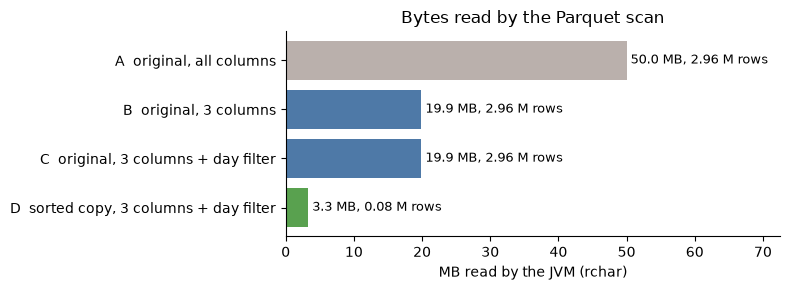

In [7]:
day = (F.col("tpep_pickup_datetime") >= "2024-01-15") & (F.col("tpep_pickup_datetime") < "2024-01-16")
cols = ["tpep_pickup_datetime", "PULocationID", "total_amount"]
variants = {
    "A  original, all columns":              spark.read.parquet(TRIPS),
    "B  original, 3 columns":                spark.read.parquet(TRIPS).select(cols),
    "C  original, 3 columns + day filter":   spark.read.parquet(TRIPS).select(cols).filter(day),
    "D  sorted copy, 3 columns + day filter": spark.read.parquet(SORTED).select(cols).filter(day),
}
reads = []
for name, df in variants.items():
    noop = lambda df=df: df.write.format("noop").mode("overwrite").save()
    noop()                                                   # warm-up
    before = jvm_read_bytes()
    _, secs = run_tagged(name, noop)
    read_mb = (jvm_read_bytes() - before) / 1e6
    m = metrics(name)
    scan = [l for l in plan(df).splitlines() if l.startswith(("PushedFilters", "ReadSchema"))]
    reads.append({"variant": name, "time s": round(secs, 2), "MB read (rchar)": round(read_mb, 1),
                  "REST inputBytes MB": m["input MB"], "input rows": m["input rows"]})
    print(name); print("   " + "\n   ".join(scan))
reads = pd.DataFrame(reads)
print(); print(reads.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(reads.variant, reads["MB read (rchar)"], color=["#BAB0AC", "#4E79A7", "#4E79A7", "#59A14F"])
for y, (mb, rows) in enumerate(zip(reads["MB read (rchar)"], reads["input rows"])):
    ax.text(mb, y, f" {mb:.1f} MB, {rows / 1e6:.2f} M rows", va="center", fontsize=9)
ax.set(title="Bytes read by the Parquet scan", xlabel="MB read by the JVM (rchar)", xlim=(0, reads["MB read (rchar)"].max() * 1.45))
ax.invert_yaxis(); plt.tight_layout(); plt.show()

*Insight: Column pruning cut the bytes read from 50.0 MB (all columns) to 19.9 MB (3 columns). The time fell from 0.74 s to 0.24 s. On the original file, the pushed day filter did not reduce the read: without statistics, the reader read all 2,964,624 rows. On the sorted copy, the reader skipped the row groups of the other days. It read 3.3 MB and 79,907 rows for the 77,033 trips of the day. The REST metric `inputBytes` (0.03 MB to 1.46 MB) does not show the real bytes of these scans; the Linux counter does.*

## 4. Python UDFs Block the Optimizer

A **Python UDF** (user-defined function) is a Python function that Spark calls on each row. Catalyst cannot see
inside it: for the optimizer, it is a black box. Two costs follow:

1. The filter cannot be pushed to the Parquet reader, because the reader does not know what the function does.
2. Each row moves from the JVM to a Python worker process and back (serialization).

A **pandas UDF** (vectorized UDF) sends batches in Apache Arrow format, which reduces the second cost but not the first.
The cell writes the day filter of Section 3 (pickups on 2024-01-15) in three ways and runs it on the sorted copy.

In [8]:
from datetime import datetime

from pyspark.sql.functions import pandas_udf

# Spark 4.2.0 feeds Parquet batches to Arrow UDFs directly ("columnar input"). With a UDF inside a filter over a
# Parquet scan, the tasks wait for the Python workers forever. Turn the feature off; the result does not change.
spark.conf.set("spark.sql.execution.arrow.pythonUDF.columnarInput.enabled", "false")

@F.udf("boolean")
def on_jan15_py(ts):
    return ts is not None and datetime(2024, 1, 15) <= ts < datetime(2024, 1, 16)

@pandas_udf("boolean")
def on_jan15_pandas(ts: pd.Series) -> pd.Series:
    return (ts >= pd.Timestamp("2024-01-15")) & (ts < pd.Timestamp("2024-01-16"))

filters = {"built-in: day filter": day,
           "Python UDF": on_jan15_py("tpep_pickup_datetime"),
           "pandas UDF": on_jan15_pandas("tpep_pickup_datetime")}
udf_rows = []
for name, cond in filters.items():
    make = lambda cond=cond: spark.read.parquet(SORTED).select(cols).filter(cond)   # a new DataFrame per run
    p = plan(make())
    pushed = next((l for l in p.splitlines() if l.startswith("PushedFilters")), "PushedFilters: none")
    python_node = [n for n in ["BatchEvalPython", "ArrowEvalPython"] if n in p]
    make().count()                                            # warm-up: starts the Python workers
    n_rows, secs = run_tagged(f"udf-{name}", lambda make=make: make().count())
    udf_rows.append({"filter": name, "rows": n_rows, "time s": round(secs, 2), "input rows": metrics(f"udf-{name}")["input rows"],
                     "Python node": python_node[0] if python_node else "-", "pushed": pushed.split(":", 1)[1].strip()[:60]})
udf_rows = pd.DataFrame(udf_rows)
print(udf_rows.to_string(index=False))

              filter  rows  time s  input rows     Python node                                                       pushed
built-in: day filter 77033    0.29       79907               - [IsNotNull(tpep_pickup_datetime), GreaterThanOrEqual(tpep_pi
          Python UDF 77033    5.83     2964606 ArrowEvalPython                                                         none
          pandas UDF 77033    0.57     2964606 ArrowEvalPython                                                         none


*Insight: All three filters return the same 77,033 trips. Only the built-in filter appears in `PushedFilters`, so only it lets the reader skip row groups. It read 79,907 rows; the UDFs read all 2,964,606. The Python UDF took 5.83 s, about 20x the built-in filter (0.29 s), because Python calls the function once per row. The pandas UDF works on whole batches and took 0.57 s, but it also read every row. Both UDFs show `ArrowEvalPython` in the plan: Spark 4 sends the data of Python UDFs in Arrow format by default.*

## 5. Adaptive Query Execution

Catalyst plans with **estimates**. Without table statistics, it estimates the size of an aggregation result from the
input size, which is often wrong by orders of magnitude. **Adaptive Query Execution** (AQE, on by default since
Spark 3.2) re-plans the query at each shuffle, with the real sizes of the finished stages. AQE can:

| AQE feature | What it does |
| :--- | :--- |
| Coalesce shuffle partitions | merges many small shuffle partitions into fewer tasks |
| Switch join strategy | turns a sort-merge join into a broadcast join if one side is small at run time |
| Split skewed partitions | splits a very large partition of a join into several tasks |

The query compares pickups and drop-offs per zone: two aggregations and a join. To make the effect visible,
`spark.sql.shuffle.partitions` is 200 (the Spark default) in this section.

In [9]:
spark.conf.set("spark.sql.shuffle.partitions", "200")

def pickups_vs_dropoffs():
    t = spark.read.parquet(TRIPS)
    pu = t.groupBy(F.col("PULocationID").alias("zone")).agg(F.count("*").alias("pickups"))
    do = t.groupBy(F.col("DOLocationID").alias("zone")).agg(F.count("*").alias("dropoffs"))
    return pu.join(do, "zone").withColumn("pickup_share", F.round(F.col("pickups") / (F.col("pickups") + F.col("dropoffs")), 3))

aqe_rows, final_plans = [], {}
for aqe in ["false", "true"]:
    spark.conf.set("spark.sql.adaptive.enabled", aqe)
    pickups_vs_dropoffs().collect()                           # warm-up
    times, dfs = [], []
    for i in range(2):                                        # a new DataFrame per run: no shuffle reuse
        dfs.append(pickups_vs_dropoffs())
        result, secs = run_tagged(f"aqe-{aqe}-{i}", dfs[-1].collect)
        times.append(secs)
    m = metrics(f"aqe-{aqe}-0")
    final_plans[aqe] = plan(dfs[0], "simple")                 # after the run: the final adaptive plan
    joins = [j for j in ["SortMergeJoin", "BroadcastHashJoin"] if j in final_plans[aqe]]
    aqe_rows.append({"AQE": aqe, "best s": round(min(times), 2), "jobs": m["jobs"], "stages": m["stages"],
                     "tasks": m["tasks"], "join in final plan": " / ".join(joins), "result rows": len(result)})
print(pd.DataFrame(aqe_rows).to_string(index=False))

  AQE  best s  jobs  stages  tasks join in final plan  result rows
false    1.02     2       4    408  BroadcastHashJoin          259
 true    0.26     4       4     10  BroadcastHashJoin          259


In [10]:
print("AQE off, physical plan:\n" + final_plans["false"])
print("AQE on, final plan after the run:\n" + final_plans["true"])

AQE off, physical plan:
== Physical Plan ==
*(4) Project [zone#501, pickups#502L, dropoffs#525L, round((cast(pickups#502L as double) / cast((pickups#502L + dropoffs#525L) as double)), 3) AS pickup_share#566]
+- *(4) BroadcastHashJoin [zone#501], [zone#524], Inner, BuildRight, false, false
   :- *(4) HashAggregate(keys=[PULocationID#489], functions=[count(1)])
   :  +- Exchange hashpartitioning(PULocationID#489, 200), ENSURE_REQUIREMENTS, [plan_id=1031]
   :     +- *(1) HashAggregate(keys=[PULocationID#489], functions=[partial_count(1)])
   :        +- *(1) Filter isnotnull(PULocationID#489)
   :           +- *(1) ColumnarToRow
   :              +- FileScan parquet [PULocationID#489] Batched: true, DataFilters: [isnotnull(PULocationID#489)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/tmp/fzth-m13/l02/trips_2024-01.parquet], PartitionFilters: [], PushedFilters: [IsNotNull(PULocationID)], ReadSchema: struct<PULocationID:int>
   +- BroadcastExchange HashedRelationBroadcast

*Insight: With AQE off, Spark ran 408 tasks: 4 per scan and 200 after each of the two shuffles. AQE saw the real size of the shuffle output and coalesced the 200 small partitions (`AQEShuffleRead coalesced`). The same query then ran 10 tasks and took 0.26 s instead of 1.02 s, about 4x faster. Both plans use a broadcast join: the planner already estimated one aggregated side below 10 MB. Lesson 04 shows a join switch by AQE. AQE ran 4 jobs instead of 2, because it runs each shuffle stage as its own job.*

| Your situation | What to check in the plan |
| :--- | :--- |
| A query reads too much | `ReadSchema` (pruned columns?), `PushedFilters`, `PartitionFilters` (Lesson 03) |
| A filter is not pushed | a Python UDF, a cast on the column, or a function the source does not support |
| Too many small tasks | `AQEShuffleRead coalesced`; is AQE on? |
| A slow join | `SortMergeJoin` vs `BroadcastHashJoin`; the sizes of both sides |

## Real-World Use Case or Analogy

Catalyst is like a **navigation app**. You give the destination (the query); the app chooses the route (the plan).
It removes detours (filter pushdown), does not load what you do not need (column pruning), and AQE is the live
traffic update: when the app sees the real traffic after the first part of the trip, it changes the rest of the route.
A Python UDF is a road that is not on the map: the app must drive it slowly and cannot plan around it.

Data teams read plans every day. A common review step for a slow Spark job is: open the SQL tab of the Spark UI,
find the scan with the most bytes, and check whether the filters were pushed. Replacing Python UDFs with built-in
functions or SQL expressions is often the cheapest fix for a slow PySpark job.

In [11]:
spark.stop()